<a href="https://colab.research.google.com/github/Tol1bjonov/AI_Electronic_Computer_Engineering_dept/blob/main/Gates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
def step(z):
    if z > 0:
        y = 1
    else:
        y = 0
    return y
def NOT(x1):
    z = -x1 + 0.5          # Weight w = -1, Bias b = 0.5
    return step(z)
print("=== NOT Gate Truth Table ===")
print(f"NOT(0) = {NOT(0)}") # Input 0 -> Output 1
print(f"NOT(1) = {NOT(1)}") # Input 1 -> Output 0

=== NOT Gate Truth Table ===
NOT(0) = 1
NOT(1) = 0


In [2]:
# 2 and gate
def step(z):
    if z > 0:
        y = 1
    else:
        y = 0
    return y
def AND(x1, x2):
    z = x1 + x2 - 1.5    # Weights w1 = 1, w2 = 1, Bias b = -1.5
    return step(z)
print("=== AND Gate Truth Table ===")
print(f"AND(0, 0) = {AND(0, 0)}")  # Input (0, 0) -> Output 0
print(f"AND(0, 1) = {AND(0, 1)}")  # Input (0, 1) -> Output 0
print(f"AND(1, 0) = {AND(1, 0)}")  # Input (1, 0) -> Output 0
print(f"AND(1, 1) = {AND(1, 1)}")  # Input (1, 1) -> Output 1

=== AND Gate Truth Table ===
AND(0, 0) = 0
AND(0, 1) = 0
AND(1, 0) = 0
AND(1, 1) = 1


In [3]:
# #### XOR just one perceptron
import numpy as np
from sklearn.linear_model import Perceptron

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])          # XOR targets

perc = Perceptron(random_state=42)  # one neuron
perc.fit(X, y)
print("Predictions:", perc.predict(X))
print(f"Accuracy: {perc.score(X, y):.0%}")

Predictions: [0 0 0 0]
Accuracy: 50%


In [4]:
# ######XOR  MLPClasifier prepare
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(2,),   # h1 and h2
    activation="logistic",     # smooth step
    solver="lbfgs",            # good for tiny data
    random_state=0,            # same start for all
)

In [5]:
# ###### Training XOR
mlp.fit(X, y)      # training happens here

print("Predictions:", mlp.predict(X))
print(f"Accuracy: {mlp.score(X, y):.0%}")

proba = mlp.predict_proba(X)[:, 1]   # P(y = 1)
print("P(y=1):", proba.round(3))

Predictions: [0 1 1 0]
Accuracy: 100%
P(y=1): [0.002 0.998 0.998 0.002]


In [6]:
# ####  Look inside:w
W1, W2 = mlp.coefs_        # weights (2 layers)
b1, b2 = mlp.intercepts_   # biases  (2 layers)
print("W1 =\n", W1.round(1))
print("b1 =", b1.round(1))
print("W2 =", W2.ravel().round(1))
print("b2 =", b2.round(1))

W1 =
 [[-7.1  6.4]
 [-6.9  6.4]]
b1 = [10.8 -2.8]
W2 = [14.1 14.3]
b2 = [-21.3]


In [7]:
# ##### sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

H = sigmoid(X @ W1 + b1)   # hidden layer
print(H.round(2))

[[1.   0.05]
 [0.98 0.97]
 [0.98 0.97]
 [0.04 1.  ]]


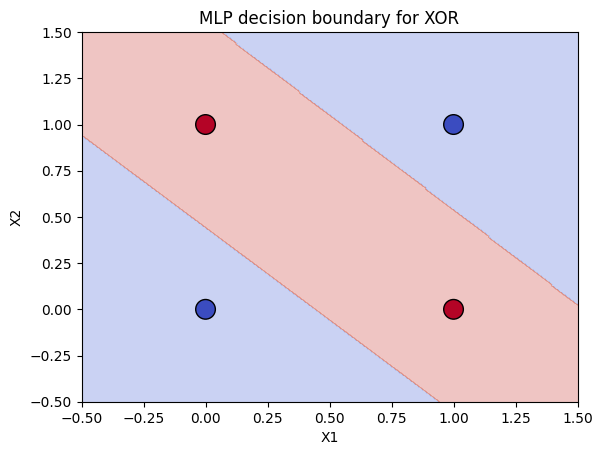

In [8]:
##  XOR boundary
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 300),
                     np.linspace(-0.5, 1.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = mlp.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm")
plt.scatter(X[:, 0], X[:, 1], c=y, s=200,
            cmap="coolwarm", edgecolors="k")
plt.xlabel("X1"); plt.ylabel("X2")
plt.title("MLP decision boundary for XOR")
plt.show()